### Experiment / Results / Model

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Image Captioning Demo
```text
├── data/
│   ├── Baseline/
│   │   └── Baseline_best_model.pt
│   ├── StrongerRegularization/
│   │   └── SR_best_model.pt
│   ├── Attention/
│   │   └── Att_best_model.pt
│   ├── Attention_ScheduledSampling/


In [12]:
import json
from pathlib import Path
from PIL import Image

import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from models import Encoder, RNNDecoder, RNNDecoderWithAttention
from datasets import CaptionDataset, collate_fn
from train import decode_caption, Config, evaluate, load_models

### Model / Path

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [2]:
# 配置
# Note on Output. Refer to the archived source for the detailed original comment.

# Note on Model, Visualization, Output. Refer to the archived source for the detailed original comment.
# 项目根目录
PROJECT_ROOT = Path('/Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成')

# Note on Dataset, File, Path, Data. Refer to the archived source for the detailed original comment.
dataset_dir = PROJECT_ROOT / 'data' / 'flickr8k-archive'     # 包含 Images/
preprocess_dir = PROJECT_ROOT / 'data'                       # 包含 vocab.json 和 captions_encoded.json

# Note on Model, Path, Check. Refer to the archived source for the detailed original comment.
output_root = PROJECT_ROOT / 'output'
ckpt_paths = {
    'Baseline': output_root / 'Baseline/Baseline_best_model.pt',
    'SR':  output_root / 'StrongerRegularization/SR_best_model.pt',
    'Att': output_root / 'Attention/Att_best_model.pt',
    'ASS': output_root / 'Attention_ScheduledSampling/ASS_best_model.pt',
    'Finetune':  output_root / 'Finetune/finetune_best_model.pt',
}

# Note on Results, Save, Output. Refer to the archived source for the detailed original comment.
comparison_dir = PROJECT_ROOT / 'comparison_results'
comparison_dir.mkdir(exist_ok=True)

print("数据集目录:", dataset_dir)
print("预处理目录:", preprocess_dir)
print("已配置以下模型检查点：")
for name, path in ckpt_paths.items():
    print(f"  {name}: {path}")

数据集目录: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/data/flickr8k-archive
预处理目录: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/data
已配置以下模型检查点：
  Baseline: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/output/Baseline/Baseline_best_model.pt
  SR: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/output/StrongerRegularization/SR_best_model.pt
  Att: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/output/Attention/Att_best_model.pt
  ASS: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/output/Attention_ScheduledSampling/ASS_best_model.pt
  Finetune: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验6-图像自然语言描述生成/output/Finetune/finetune_best_model.pt


In [3]:
# 导入 Config 后，修改实例属性
cfg = Config()
cfg.dataset_dir = str(dataset_dir)

# 自动选择可用设备
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Using device: mps


### Model / Testing / Dataset

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [4]:
# Note on Testing, Dataset, Load, Data. Refer to the archived source for the detailed original comment.
test_transform = transforms.Compose(
    [
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

test_dataset = CaptionDataset(
    cfg.dataset_dir,                 # 图片根目录
    #Note on File. Refer to the archived source for the detailed original comment.
    split="test", 
    transform=test_transform, 
    cache=False
)
print(f"测试集大小: {len(test_dataset):,} 个描述")
print(f"测试集图片数量: {len(test_dataset.img_names):,} 张")

vocab = test_dataset.vocab
rev_vocab = test_dataset.rev_vocab
vocab_size = len(vocab)


测试集大小: 5,000 个描述
测试集图片数量: 1,000 张


### Model / Save / Load

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [5]:
# Note on Model, Load. Refer to the archived source for the detailed original comment.
from eval_checkpoints import load_checkpoint_model
# encoder, decoder = load_models(vocab_size, cfg)

# Note on Model, Save, Load, Weights. Refer to the archived source for the detailed original comment.
# checkpoint = torch.load(model_path, map_location=device)

# Note on Load, Weights. Refer to the archived source for the detailed original comment.
# try:
#     encoder.load_state_dict(checkpoint["encoder"])
#     decoder.load_state_dict(checkpoint["decoder"])
# except RuntimeError as e:
#     Note on Check. Refer to the archived source for the detailed original comment.

models = {}
for name, ckpt_path in ckpt_paths.items():
    print(f"\n加载模型: {name}")
    encoder, decoder, cfg_model = load_checkpoint_model(ckpt_path, vocab_size, device)
    models[name] = {
        'encoder': encoder,
        'decoder': decoder,
        'cfg': cfg_model
    }
    encoder.eval()
    decoder.eval()
print("\n所有模型加载完成！")


加载模型: Baseline

加载模型: SR

加载模型: Att

加载模型: ASS

加载模型: Finetune

所有模型加载完成！


### Results / Model / Validation

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [6]:
csv_path_val = output_root / 'beam_search_comparison_val.csv'
df_val = pd.read_csv(csv_path_val)
# Note on File. Refer to the archived source for the detailed original comment.
df_val['model_name'] = df_val['path'].apply(lambda x: Path(x).stem.replace('_best_model', ''))

print("=== 验证集各模型的 最佳 BLEU-4 分数 ===")
val_best_per_model = df_val.loc[df_val.groupby('model_name')['bleu4'].idxmax()].sort_values('bleu4', ascending=False)
print(val_best_per_model[['model_name', 'beam_size', 'bleu4', 'use_attention', 'finetune_encoder']].to_string(index=False))

# 找出最佳配置
best_row_val = df_val.loc[df_val['bleu4'].idxmax()]
print(f"\n 最佳模型: {best_row_val['model_name']} (beam_size={best_row_val['beam_size']}, BLEU-4={best_row_val['bleu4']:.4f})")

=== 验证集各模型的 最佳 BLEU-4 分数 ===
model_name  beam_size    bleu4  use_attention  finetune_encoder
  finetune          3 0.234307           True              True
       ASS          5 0.231140           True             False
        SR          3 0.208718          False             False
  Baseline          3 0.208570          False             False
       Att          3 0.204927           True             False

 最佳模型: finetune (beam_size=3, BLEU-4=0.2343)


=== 各模型 验证集 最佳 BLEU-4 分数 ===


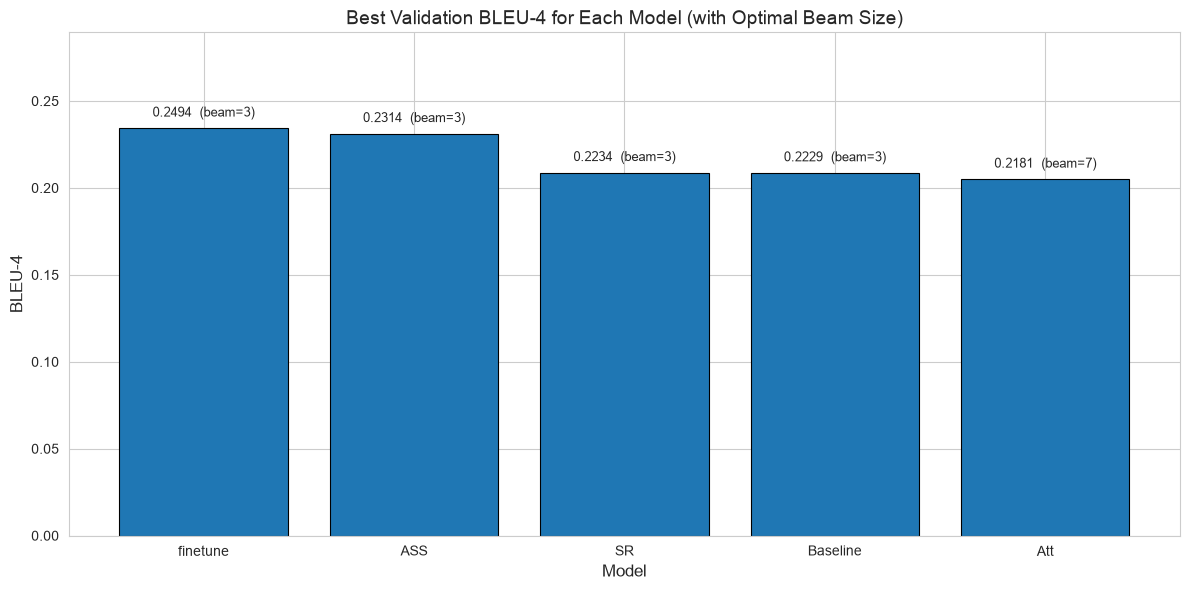

In [13]:
# Note on Results, Validation, Visualization. Refer to the archived source for the detailed original comment.
print("=== 各模型 验证集 最佳 BLEU-4 分数 ===")

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    val_best_per_model['model_name'],
    val_best_per_model['bleu4'],
    edgecolor='black',
    linewidth=0.8
)

ax.set_title('Best Validation BLEU-4 for Each Model (with Optimal Beam Size)', fontsize=14)
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('BLEU-4', fontsize=12)

# 在每个柱子上方标注 BLEU-4 和对应的 beam size
for bar, (_, row) in zip(bars, best_per_model.iterrows()):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{row['bleu4']:.4f}  (beam={int(row['beam_size'])})",
        ha='center', va='bottom', fontsize=9
    )

# 适当调整 y 轴上限，给标注留空间
ax.set_ylim(0, best_per_model['bleu4'].max() + 0.04)
plt.tight_layout()
plt.show()

=== 各模型 验证集 Greedy BLEU-4 分数 ===
model_name    bleu4
  Baseline 0.183693
        SR 0.183852
       Att 0.190013
  finetune 0.206737
       ASS 0.207708


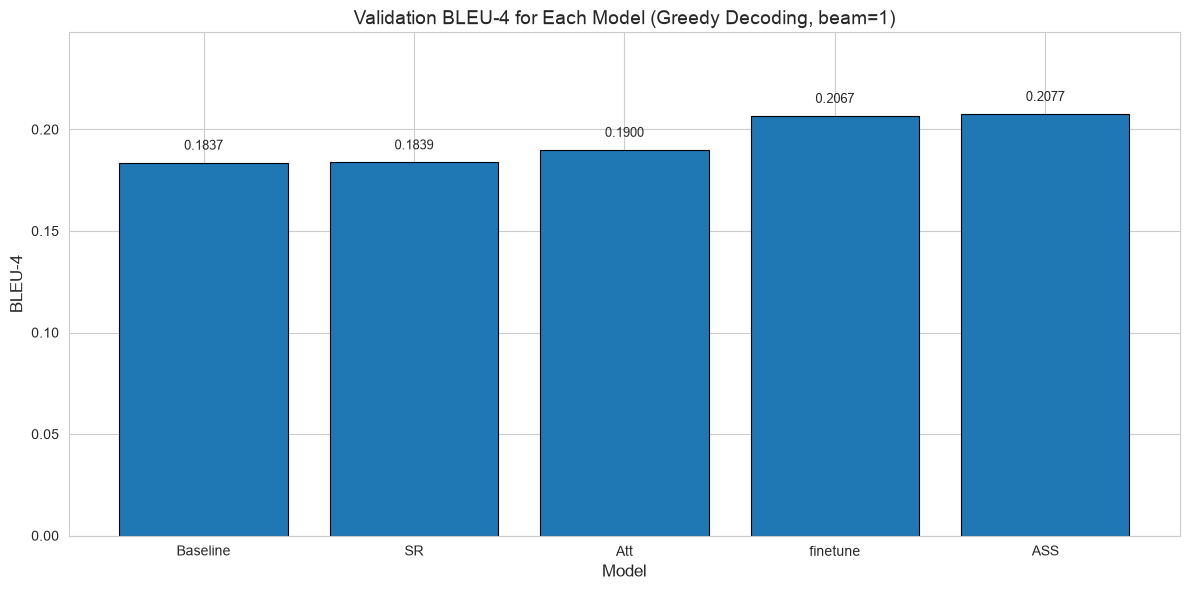

In [17]:
# Note on Validation. Refer to the archived source for the detailed original comment.
# 筛选 greedy (beam=1)
val_greedy = df_val[df_val['beam_size'] == 1].sort_values('bleu4', ascending=True)

print("=== 各模型 验证集 Greedy BLEU-4 分数 ===")
print(val_greedy[['model_name', 'bleu4']].to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(
    val_greedy['model_name'],
    val_greedy['bleu4'],
    edgecolor='black',
    linewidth=0.8
)

ax.set_title('Validation BLEU-4 for Each Model (Greedy Decoding, beam=1)', fontsize=14)
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('BLEU-4', fontsize=12)

# 在每个柱子上方标注 BLEU-4 值
for bar, (_, row) in zip(bars, val_greedy.iterrows()):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{row['bleu4']:.4f}",
        ha='center', va='bottom', fontsize=9
    )

ax.set_ylim(0, val_greedy['bleu4'].max() + 0.04)
plt.tight_layout()
plt.show()

### Model / Visualization / Run

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [7]:
# Note on Testing, Visualization. Refer to the archived source for the detailed original comment.
import random

# 随机选择5张图片
sample_indices = random.sample(range(len(test_dataset.img_names)), 5)
print(f"选择的图片索引: {', '.join(map(str, sample_indices))}")

选择的图片索引: 908, 990, 820, 726, 323


### Model / Visualization / Output

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [8]:
# Note on Model, Validation. Refer to the archived source for the detailed original comment.
best_beam = {
    "Baseline": 3,
    "SR": 3,
    "Att": 3,
    "ASS": 5,
    "Finetune": 3,
}

# Note on Visualization. Refer to the archived source for the detailed original comment.
# Note on Visualization, Generate. Refer to the archived source for the detailed original comment.
with torch.no_grad():
    for i, img_idx in enumerate(sample_indices):
        # Note on Path. Refer to the archived source for the detailed original comment.
        img_name = test_dataset.img_names[img_idx]
        img_path = test_dataset.img_dir / img_name

        # Note on Load. Refer to the archived source for the detailed original comment.
        original_img = Image.open(img_path).convert('RGB')
        
        # Note on Model, Input. Refer to the archived source for the detailed original comment.
        # 找到该图片对应的第一个描述的索引
        cap_idx = img_idx * test_dataset.cpi
        # Note on Model, Input, Use. Refer to the archived source for the detailed original comment.
        model_input, _, _ = test_dataset[cap_idx]
        model_input = model_input.unsqueeze(0).to(device)

        # Note on Generate. Refer to the archived source for the detailed original comment.
        # features = encoder(model_input)
        # generated_caption = decoder.generate_caption(features, vocab)
        # decoded_caption = decode_caption(generated_caption[0], rev_vocab)

        # 获取真实描述
        real_captions = []
        for j in range(test_dataset.cpi):
            _, cap, _ = test_dataset[cap_idx + j]
            real_captions.append(decode_caption(cap, rev_vocab))

        # Note on Model, Generate. Refer to the archived source for the detailed original comment.
        model_outputs = {}
        for name, model_dict in models.items():
            enc = model_dict['encoder']
            dec = model_dict['decoder']
            # Note on Model, Use. Refer to the archived source for the detailed original comment.
            beam = best_beam.get(name, 3)  # 默认 beam=3
            features = enc(model_input)
            pred = dec.generate_caption(features, vocab, beam_size=beam, max_len=30)
            decoded = decode_caption(pred[0], rev_vocab)
            model_outputs[name] = decoded
            
        # 显示图片
        plt.figure(figsize=(8, 8))
        plt.imshow(original_img)
        plt.axis('off')
        plt.title(f"Image {i+1}: {img_name}")
        plt.tight_layout()
        plt.show()
        
        # 打印对比信息
        print(f"\n===== Image {i+1}: {img_name} =====")
        print("【真实描述】")
        for j, cap in enumerate(real_captions, 1):
            print(f"  {j}. {cap}")
        print("【模型生成】")
        for name, cap in model_outputs.items():
            print(f"  {name}: {cap}")
        print("=" * 50)

<Figure size 800x800 with 1 Axes>


===== Image 1: 2991994415_504d1c0a03.jpg =====
【真实描述】
  1. A girl dressed in a red dress and another girl dressed as a pirate are playing around.
  2. Girls dressed in red and black costumes hold a wrestling pose.
  3. Two girls dress up for halloween.
  4. Two girls in red costumes play together.
  5. Two little girls in red and black costumes are posing for a picture.
【模型生成】
  Baseline: A man in a red and black dress and black and white woman with black <unk>.
  SR: A man in a red and red outfit is holding a red and red woman in a red dress.
  Att: A young girl in a red outfit.
  ASS: A man in a red costume and a red <unk>.
  Finetune: Two women in a red and red dress.


<Figure size 800x800 with 1 Axes>


===== Image 2: 241345844_69e1c22464.jpg =====
【真实描述】
  1. A coach speaking to a football player while <unk> watches.
  2. A football player from <unk> talks to the coach about the game.
  3. A football player is talking to his coach.
  4. The <unk> official and football player are talking in front a crowd and other team members.
  5. The coach talks it over with his quarterback during a <unk>.
【模型生成】
  Baseline: A group of football players are tackling a football.
  SR: A group of football players playing football.
  Att: A football player in a red and white uniform.
  ASS: A group of football players in a field.
  Finetune: A group of football players in a crowd.


<Figure size 800x800 with 1 Axes>


===== Image 3: 500446858_125702b296.jpg =====
【真实描述】
  1. A small white dog is running through the dirt right on the outside of a patch of grass where two people and another small black dog are playing.
  2. A small white dog runs.
  3. A white dog is running on gravel away from two people and a black and brown dog.
  4. White dog outside with two people in background.
  5. White fluffy dog running in the dirt.
【模型生成】
  Baseline: A small white dog with a pink collar is running.
  SR: A white dog is carrying a stick in his mouth.
  Att: A small white dog with a stick in his mouth.
  ASS: A white dog is running in the grass.
  Finetune: A white dog runs through the grass.


<Figure size 800x800 with 1 Axes>


===== Image 4: 3058439373_9276a4702a.jpg =====
【真实描述】
  1. A crowd of people are standing in front of <unk> style buildings.
  2. A crowd of people stand looking at somthing in a european courtyard.
  3. A crowd of people stands <unk> in a plaza with buildings in the background.
  4. A group of people are looking at the buildings.
  5. Group of people standing in the town square looking up.
【模型生成】
  Baseline: A group of people are standing in front of a building.
  SR: A group of people are standing in front of a building.
  Att: A group of people are walking on the street.
  ASS: A group of people in the street.
  Finetune: A group of people walking in a street.


<Figure size 800x800 with 1 Axes>


===== Image 5: 3499720588_c32590108e.jpg =====
【真实描述】
  1. A dark skinned man plays a blue guitar on the street.
  2. A man playing his guitar on the street surrounded by buildings and street lights.
  3. A man plays a blue guitar on the an empty urban street.
  4. A man walking the streets while playing the guitar.
  5. The man plays his guitar on the <unk> streets.
【模型生成】
  Baseline: A woman in a red shirt and black pants is holding a sign.
  SR: A woman in a red shirt is holding a red umbrella.
  Att: A man in a black jacket is holding a sign on a street.
  ASS: A man in a black jacket is walking down a street.
  Finetune: A man in a black coat is standing on a street.


### Results / Model / Testing

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [9]:
# Note on Load, File. Refer to the archived source for the detailed original comment.
csv_path = output_root / 'beam_search_comparison_test.csv'
df = pd.read_csv(csv_path)
# Note on File. Refer to the archived source for the detailed original comment.
df['model_name'] = df['path'].apply(lambda x: Path(x).stem.replace('_best_model', ''))

# Note on Data. Refer to the archived source for the detailed original comment.
print("=== 各模型在不同 Beam Size 下的 BLEU-4 分数 ===")
print(df[['model_name', 'beam_size', 'bleu4', 'use_attention', 'finetune_encoder']].to_string(index=False))

# 找出最佳配置
best_row = df.loc[df['bleu4'].idxmax()]
print(f"\n 最佳模型: {best_row['model_name']} (beam_size={best_row['beam_size']}, BLEU-4={best_row['bleu4']:.4f})")

=== 各模型在不同 Beam Size 下的 BLEU-4 分数 ===
model_name  beam_size    bleu4  use_attention  finetune_encoder
  Baseline          1 0.196317          False             False
  Baseline          3 0.223381          False             False
  Baseline          5 0.216775          False             False
  Baseline          7 0.212904          False             False
        SR          1 0.200375          False             False
        SR          3 0.222857          False             False
        SR          5 0.215430          False             False
        SR          7 0.212629          False             False
       Att          1 0.182092           True             False
       Att          3 0.209860           True             False
       Att          5 0.209826           True             False
       Att          7 0.218127           True             False
       ASS          1 0.212168           True             False
       ASS          3 0.231448           True             False
  

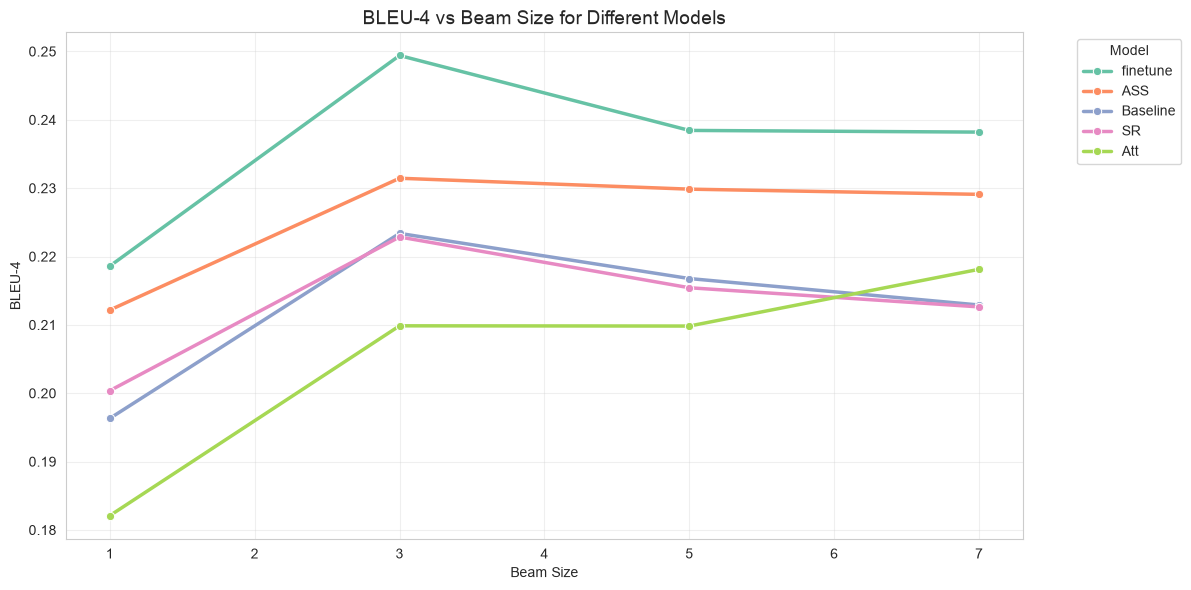

In [10]:
# Note on Settings. Refer to the archived source for the detailed original comment.
sns.set_style("whitegrid")

# 颜色映射
# Note on Results, Model. Refer to the archived source for the detailed original comment.
best_per_model = df.loc[df.groupby('model_name')['bleu4'].idxmax()].sort_values('bleu4', ascending=False)
model_order = best_per_model['model_name'].tolist()

# Note on Use, Generate. Refer to the archived source for the detailed original comment.
palette_colors = sns.color_palette("Set2", n_colors=len(model_order))
color_dict = dict(zip(model_order, palette_colors))

# Note on Model. Refer to the archived source for the detailed original comment.
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='beam_size', y='bleu4', hue='model_name', 
             hue_order=model_order,          # 保证图例顺序与柱状图一致
             palette=color_dict,
             marker='o', linewidth=2.5)
plt.title('BLEU-4 vs Beam Size for Different Models', fontsize=14)
plt.xlabel('Beam Size')
plt.ylabel('BLEU-4')
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== 各模型的 最佳 BLEU-4 分数 ===
   model_name  beam_size     bleu4  use_attention  finetune_encoder
17   finetune          3  0.249404           True              True
13        ASS          3  0.231448           True             False
1    Baseline          3  0.223381          False             False
5          SR          3  0.222857          False             False
11        Att          7  0.218127           True             False


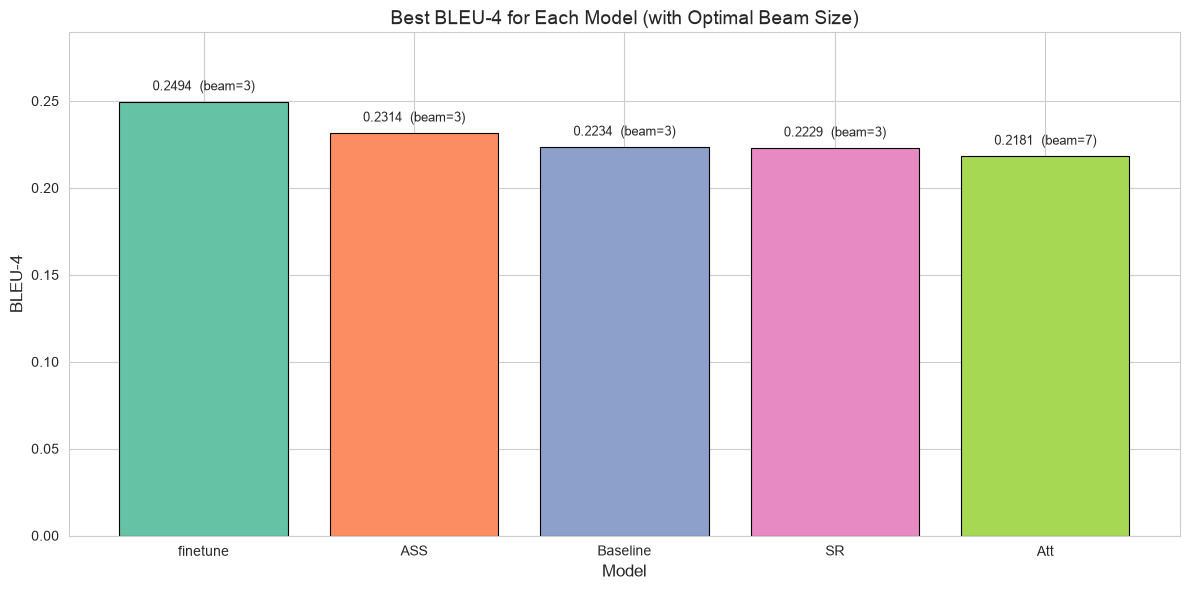

In [11]:
# Note on Model. Refer to the archived source for the detailed original comment.
print("=== 各模型的 最佳 BLEU-4 分数 ===")
print(best_per_model[['model_name', 'beam_size', 'bleu4', 'use_attention', 'finetune_encoder']])

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    best_per_model['model_name'],
    best_per_model['bleu4'],
    color=[color_dict[m] for m in best_per_model['model_name']],
    edgecolor='black',
    linewidth=0.8
)

ax.set_title('Best BLEU-4 for Each Model (with Optimal Beam Size)', fontsize=14)
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('BLEU-4', fontsize=12)

# 在每个柱子上方标注 BLEU-4 和对应的 beam size
for bar, (_, row) in zip(bars, best_per_model.iterrows()):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{row['bleu4']:.4f}  (beam={int(row['beam_size'])})",
        ha='center', va='bottom', fontsize=9
    )

# 适当调整 y 轴上限，给标注留空间
ax.set_ylim(0, best_per_model['bleu4'].max() + 0.04)
plt.tight_layout()
plt.show()

### Results / Summary / Model

This cell documents the image caption generation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.
